# Logistic Regression for Classification

The case study uses the **AI4I 2020 Predictive Maintenance Dataset** from the UCI Machine Learning Repository to classify machine failures from process variables.

Data source: https://archive.ics.uci.edu/dataset/601


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

FIG_DIR = Path("figures")
DATA_DIR = Path("data")
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "ai4i2020_predictive_maintenance.csv"


## Problem and model

The guiding problem in this lesson is predictive maintenance:

$$
P(\text{failure}=1 \mid \text{measurements})
$$

We have labeled examples

$$
\mathcal{D}=\{(x_i,y_i)\}_{i=1}^{n}, \qquad x_i \in \mathbb{R}^p,\quad y_i \in \{0,1\}.
$$

A simple linear model produces a score

$$
z_i=\beta_0+\beta^T x_i,
$$

but this score can take any real value. To obtain a probability, we transform it with the logistic function:

$$
\hat p(y=1\mid x)=\sigma(\beta_0+\beta^T x), \qquad
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

After estimating the probability, we choose a threshold $\tau$:

$$
\hat y =
\begin{cases}
1, & \hat p \geq \tau,\\
0, & \hat p < \tau.
\end{cases}
$$

The threshold is a risk and cost decision: a low $\tau$ increases failure alarms and recall; a high $\tau$ reduces alarms and tends to increase precision.


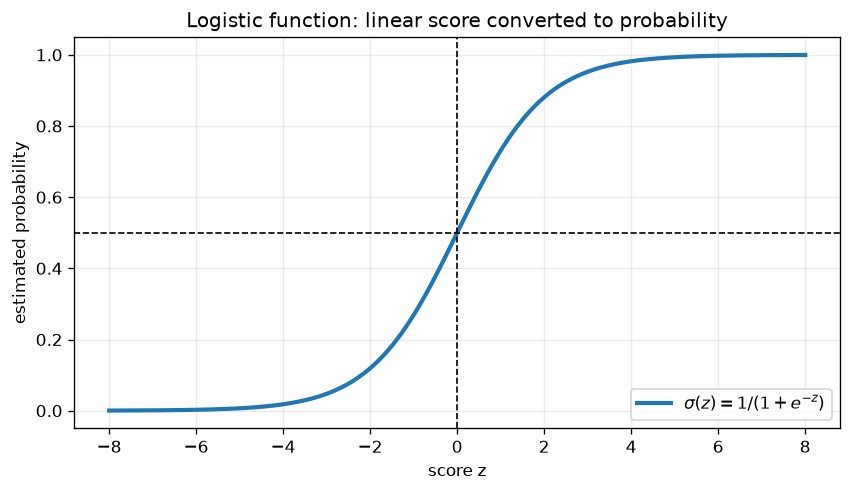

In [2]:
z = np.linspace(-8, 8, 500)
sigma = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(z, sigma, color="#1f77b4", linewidth=2.5, label=r"$\sigma(z)=1/(1+e^{-z})$")
ax.axhline(0.5, color="black", linewidth=1, linestyle="--")
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.set_xlabel("score z")
ax.set_ylabel("estimated probability")
ax.set_title("Logistic function: linear score converted to probability")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "logreg_sigmoid.png", bbox_inches="tight")
plt.show()

## Logit: where the linear component appears

Logistic regression is linear in the log-odds:

$$
\text{logit}(p)
=
\log\left(\frac{p}{1-p}\right)
=
\beta_0+\beta^T x.
$$

Therefore, the model is not linear in the probability itself; it is linear in the **logit**.


## Training, loss, and regularization

To train the model, we choose the parameters

$$
\beta_0,\beta_1,\ldots,\beta_p
$$

that minimize the log loss:

$$
J(\beta)=
-\frac{1}{n}\sum_{i=1}^{n}
\left[
y_i\log(\hat p_i)
+(1-y_i)\log(1-\hat p_i)
\right].
$$

If $y_i=1$, the individual loss is $J_i=-\log(\hat p_i)$.  
If $y_i=0$, the individual loss is $J_i=-\log(1-\hat p_i)$.

With L2 penalty:

$$
J_{\text{reg}}(\beta)=J(\beta)+\lambda\sum_{j=1}^{p}\beta_j^2.
$$

Regularization prevents excessively large coefficients and helps reduce overfitting. Since variables use different units, scaling is an important part of the pipeline.


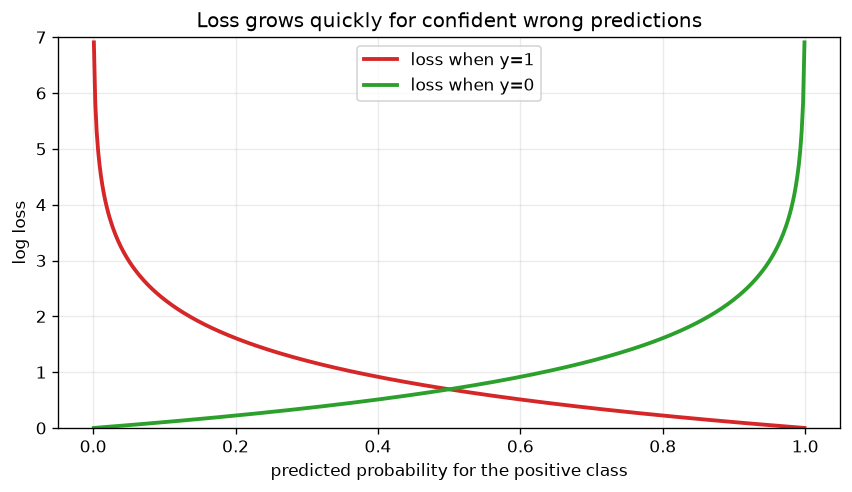

In [3]:
p = np.linspace(0.001, 0.999, 500)
loss_y1 = -np.log(p)
loss_y0 = -np.log(1 - p)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(p, loss_y1, label="loss when y=1", color="#d62728", linewidth=2.3)
ax.plot(p, loss_y0, label="loss when y=0", color="#2ca02c", linewidth=2.3)
ax.set_ylim(0, 7)
ax.set_xlabel("predicted probability for the positive class")
ax.set_ylabel("log loss")
ax.set_title("Loss grows quickly for confident wrong predictions")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "logreg_logloss.png", bbox_inches="tight")
plt.show()

## Training pipeline

A compact form of the pipeline is:

```python
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42)),
])
```

In the case study below, we use only numerical variables and scale them with `StandardScaler`. We also set `class_weight="balanced"` because failures are rare.


## AI4I 2020 dataset

The **AI4I 2020 Predictive Maintenance Dataset** contains 10,000 operating samples from an industrial machine.

- target: `Machine failure`;
- 339 failures;
- failures are rare;
- model features: air temperature, process temperature, rotational speed, torque, and tool wear.

The local CSV file is used when available.


In [4]:
df = pd.read_csv(DATA_PATH)

print(df.shape)
df.head()

(10000, 7)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [5]:
target = "Machine failure"
X = df.drop(columns=[target])
y = df[target].astype(int)

print(df.info())
print("\nClass distribution:")
print(y.value_counts().rename(index={0: "no failure", 1: "failure"}))
print("\nFailure rate: {:.2f}%".format(100 * y.mean()))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type                 10000 non-null  str    
 1   Air temperature      10000 non-null  float64
 2   Process temperature  10000 non-null  float64
 3   Rotational speed     10000 non-null  int64  
 4   Torque               10000 non-null  float64
 5   Tool wear            10000 non-null  int64  
 6   Machine failure      10000 non-null  int64  
dtypes: float64(3), int64(3), str(1)
memory usage: 547.0 KB
None

Class distribution:
Machine failure
no failure    9661
failure        339
Name: count, dtype: int64

Failure rate: 3.39%


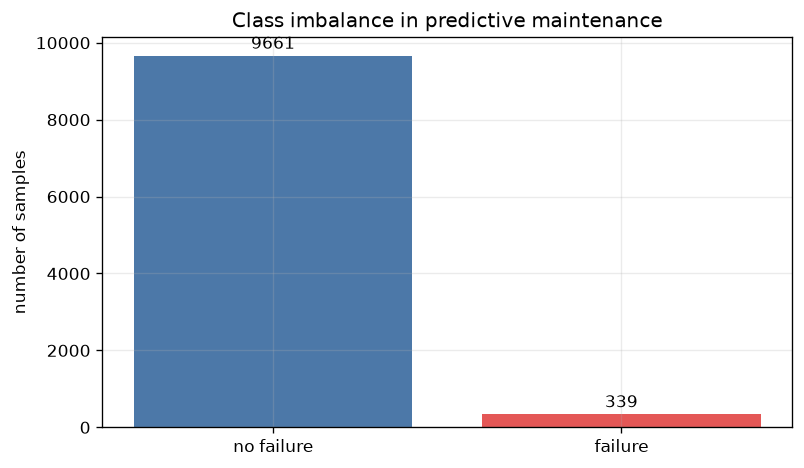

In [6]:
class_counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.8, 4.0))
bars = ax.bar(["no failure", "failure"], class_counts.values, color=["#4c78a8", "#e45756"])
ax.set_ylabel("number of samples")
ax.set_title("Class imbalance in predictive maintenance")
for bar, value in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 80, str(value), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIG_DIR / "logreg_balancing.png", bbox_inches="tight")
plt.show()

## Training with `scikit-learn`

The train/test split is stratified to preserve approximately the same failure proportion in both sets. The model uses numerical features only, estimates probabilities with `predict_proba`, and predicts classes by comparing each probability with the threshold $\tau=0{,}5$.


In [7]:
numeric_features = ["Air temperature", "Process temperature", "Rotational speed", "Torque", "Tool wear"]
X_model = X[numeric_features]

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.25, random_state=42, stratify=y
)

model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0, random_state=42)),
    ]
)

model.fit(X_train, y_train)
y_proba = model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
}
pd.Series(metrics).to_frame("value")


,value
accuracy,0.820000
precision,0.135729
recall,0.800000
f1,0.232082


## Test-set results

Using the pipeline with numerical features only, the results are:

- accuracy: 0.820;
- precision: 0.136;
- recall: 0.800;
- $F_1$: 0.232.

Overall accuracy appears high, but low precision indicates many false alarms. High recall means the model detects a large share of actual failures.


In [8]:
print(classification_report(y_test, y_pred, target_names=["no failure", "failure"], digits=3))

              precision    recall  f1-score   support

  no failure      0.991     0.821     0.898      2415
     failure      0.136     0.800     0.232        85

    accuracy                          0.820      2500
   macro avg      0.564     0.810     0.565      2500
weighted avg      0.962     0.820     0.875      2500



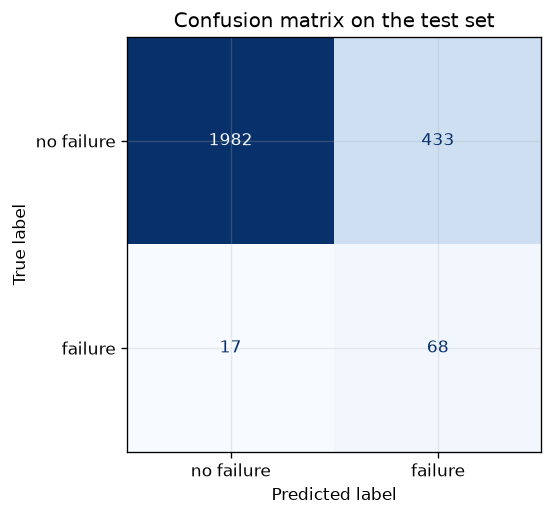

In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.4, 4.4))
disp = ConfusionMatrixDisplay(cm, display_labels=["no failure", "failure"])
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Confusion matrix on the test set")
fig.tight_layout()
fig.savefig(FIG_DIR / "logreg_confusion_matrix.png", bbox_inches="tight")
plt.show()

## Cost-based threshold selection

If a missed failure costs more than an additional inspection, choose the threshold $\tau$ that minimizes:

$$
C(\tau)=c_{FP}FP(\tau)+c_{FN}FN(\tau).
$$

Use the data as follows:

- training: fit the model parameters;
- validation: choose the threshold $\tau$ that minimizes cost;
- test: evaluate final performance with $\tau$ fixed.

The cost curve below is computed on the validation set.


threshold      0.430000
FP           370.000000
FN             7.000000
cost         545.000000
precision      0.131455
recall         0.888889
Name: 76, dtype: float64


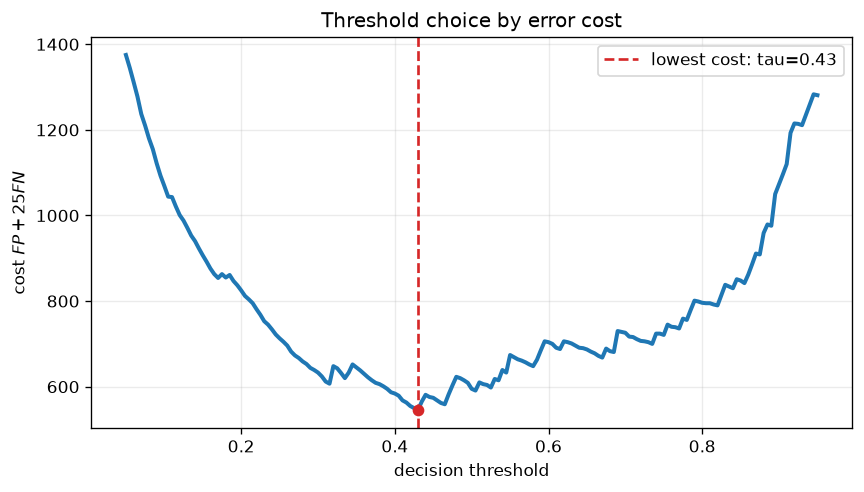

In [10]:
# Relative costs of the didactic example: a false negative costs 25 times a false positive.
c_fp = 1
c_fn = 25

# The threshold must be chosen on validation, not on test.
# Therefore, split off part of the training set to validate thresholds.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

# This model is trained only on X_fit; the test set remains held out.
threshold_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0, random_state=42)),
    ]
)
threshold_model.fit(X_fit, y_fit)
y_val_proba = threshold_model.predict_proba(X_val)[:, 1]

# Computes FP, FN and cost for each threshold using validation only.
threshold_grid = np.linspace(0.05, 0.95, 181)
cost_rows = []
for th in threshold_grid:
    pred = (y_val_proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    cost_rows.append({
        "threshold": th,
        "FP": fp,
        "FN": fn,
        "cost": c_fp * fp + c_fn * fn,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
    })

cost_df = pd.DataFrame(cost_rows)
# Threshold minimizing cost on validation.
best_cost = cost_df.loc[cost_df["cost"].idxmin()]
print(best_cost)

fig, ax = plt.subplots(figsize=(7.3, 4.2))
ax.plot(cost_df["threshold"], cost_df["cost"], color="#1f77b4", linewidth=2.4)
ax.axvline(best_cost["threshold"], color="#d62728", linestyle="--", linewidth=1.6,
           label=f"lowest cost: tau={best_cost['threshold']:.2f}")
ax.scatter([best_cost["threshold"]], [best_cost["cost"]], color="#d62728", zorder=3)
ax.set_xlabel("decision threshold")
ax.set_ylabel(r"cost $FP + 25 FN$")
ax.set_title("Threshold choice by error cost")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "logreg_threshold_cost.png", bbox_inches="tight")
plt.show()

## Comparison with KNN

For comparison with the previous lesson, we use the same numerical features, scaling, train/test split, and $\tau=0{,}5$.

KNN with $k=15$ was more selective: it produced few false alarms but missed many failures. Logistic regression was more safety-oriented, with higher recall.


In [11]:
knn_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=15, weights="distance")),
    ]
)

models = {
    "Log. regression": model,
    "KNN (k=15)": knn_model,
}

comparison_rows = []
for name, clf in models.items():
    clf.fit(X_train, y_train)
    proba = clf.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    comparison_rows.append({
        "Model": name,
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
comparison_df

,Recall,Precision,F1
Model,,,
Log. regression,0.800000,0.135729,0.232082
KNN (k=15),0.235294,0.869565,0.370370


## Summary

1. Logistic regression estimates $P(y=1\mid x)$.
2. The sigmoid maps a linear score to a probability.
3. Training minimizes regularized log loss.
4. The probability is converted into a decision using a threshold $\tau$.
5. In engineering, choose $\tau$ based on the cost of errors.

## References

- GRUS, Joel. *Data Science do Zero: Noções Fundamentais com Python*. 2nd ed. Alta Books, 2020.
- UCI Machine Learning Repository: AI4I 2020 Predictive Maintenance Dataset. https://archive.ics.uci.edu/dataset/601
- Pedregosa et al. *Scikit-learn: Machine Learning in Python*. JMLR, 2011.
